# NOTEBOOK 9: Schematic figures — OSD-420

**The Spleen Machine (OSD-420-3)** · Kireeti, Pranav, Aryan, Vedant · Interlake High School

The five drawn figures in the deck: the mission and study design, the analysis pipeline, the
biological model, the experimental design for the three aims, and the expected results.

These are hand-authored SVG rendered to PNG with `cairosvg`, in the visual language BioRender
uses — one surface colour, one ink pair, flat cards with thin strokes, generous whitespace, no
gradients or drop shadows. Building them as SVG rather than in a drawing tool means every figure
is reproducible from this notebook, and a colour or a number can be changed in one place.

**Attribution.** All five are our own drawings, so each carries the line *"Image produced by
The Spleen Machine for the 2026 Capstone Showcase"* on the slide. If you swap any of these for a
BioRender export, that figure needs BioRender's own attribution line instead, and a figure taken
from a journal needs its Creative Commons or permission wording.

This notebook has **no data dependency** — it does not read `results/`, so it runs on its own.

## Setup

`cairosvg` is not preinstalled in Colab.

In [1]:
!pip install -q cairosvg

In [2]:
#!/usr/bin/env python3
"""
BioRender-style schematic figures, hand-authored as SVG and rendered to PNG.

Same visual language as the data figures: one surface, one ink pair, the
validated categorical hues, rounded cards, thin strokes, generous whitespace.
"""
import os

import cairosvg

FIG = "figures"
os.makedirs(FIG, exist_ok=True)

SURFACE = "#ffffff"
INK = "#171310"
INK2 = "#574e43"
MUTED = "#8c8175"
LINE = "#ded4c2"
BLUE = "#14876b"      # teal-green
ORANGE = "#a34517"    # terracotta
AQUA = "#7c42ab"      # plum
RED = "#a34517"       # terracotta (down in flight)
VIOLET = "#6e655b"    # neutral, for the non-module theme
YELLOW = "#b58a2b"
BLUE_L = "#e2f2ec"
ORANGE_L = "#f8ece3"
AQUA_L = "#efe8f7"
VIOLET_L="#f0eadf"
RED_L = "#f8ece3"
GREYCARD = "#f3ede1"

FONT = "Carlito, Calibri, sans-serif"

DEFS = f"""
<defs>
  <marker id="arrow" viewBox="0 0 10 10" refX="9" refY="5"
          markerWidth="7" markerHeight="7" orient="auto-start-reverse">
    <path d="M 0 0 L 10 5 L 0 10 z" fill="{INK2}"/>
  </marker>
  <marker id="arrowb" viewBox="0 0 10 10" refX="9" refY="5"
          markerWidth="7" markerHeight="7" orient="auto-start-reverse">
    <path d="M 0 0 L 10 5 L 0 10 z" fill="{BLUE}"/>
  </marker>
  <marker id="arrowr" viewBox="0 0 10 10" refX="9" refY="5"
          markerWidth="7" markerHeight="7" orient="auto-start-reverse">
    <path d="M 0 0 L 10 5 L 0 10 z" fill="{RED}"/>
  </marker>
  <marker id="tee" viewBox="0 0 10 10" refX="5" refY="5"
          markerWidth="7" markerHeight="7" orient="auto-start-reverse">
    <path d="M 5 0 L 5 10" stroke="{RED}" stroke-width="2.6" fill="none"/>
  </marker>
</defs>
"""


# ---------------------------------------------------------------- helpers ---
def card(x, y, w, h, fill, stroke, r=3, sw=1.4, op=1.0):
    return (f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="{r}" ry="{r}" '
            f'fill="{fill}" fill-opacity="{op}" stroke="{stroke}" stroke-width="{sw}"/>')


def txt(x, y, s, size=15, fill=INK, weight="normal", anchor="start", ls=None, op=1.0):
    extra = f' letter-spacing="{ls}"' if ls else ""
    return (f'<text x="{x}" y="{y}" font-family="{FONT}" font-size="{size}" '
            f'fill="{fill}" fill-opacity="{op}" font-weight="{weight}" '
            f'text-anchor="{anchor}"{extra}>{s}</text>')


def wrap(x, y, lines, size=14, fill=INK2, lh=19, anchor="start", weight="normal"):
    return "".join(txt(x, y + i * lh, s, size, fill, weight, anchor)
                   for i, s in enumerate(lines))


def arrow(x1, y1, x2, y2, col=INK2, w=2.0, marker="arrow", dash=None):
    d = f' stroke-dasharray="{dash}"' if dash else ""
    return (f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="{col}" '
            f'stroke-width="{w}" marker-end="url(#{marker})" stroke-linecap="round"{d}/>')


def mouse(cx, cy, s=1.0, fill="#cfc6b6", stroke=INK2):
    """Simple side-view mouse silhouette."""
    return (f'<g transform="translate({cx},{cy}) scale({s})" stroke="{stroke}" '
            f'stroke-width="1.4" fill="{fill}" stroke-linejoin="round">'
            f'<ellipse cx="0" cy="0" rx="21" ry="13"/>'
            f'<circle cx="19" cy="-5" r="9"/>'
            f'<circle cx="21" cy="-13" r="4.5"/>'
            f'<circle cx="25" cy="-6" r="1.6" fill="{stroke}" stroke="none"/>'
            f'<path d="M -20 2 C -34 2 -36 -8 -30 -12" fill="none"/>'
            f'<path d="M -8 12 l 0 7 M 4 12 l 0 7" stroke-width="2.4" fill="none"/>'
            f'</g>')


def spleen(cx, cy, s=1.0, fill="#e7b79a", stroke="#8f4a22"):
    return (f'<g transform="translate({cx},{cy}) scale({s})">'
            f'<path d="M 0 -34 C 22 -30 30 -6 24 16 C 19 33 2 40 -11 33 '
            f'C -25 25 -26 2 -20 -16 C -15 -29 -8 -35 0 -34 Z" '
            f'fill="{fill}" stroke="{stroke}" stroke-width="2"/>'
            f'<path d="M -16 -12 C -6 -6 2 2 6 16" fill="none" stroke="{stroke}" '
            f'stroke-width="1.5" stroke-opacity="0.55"/>'
            f'<circle cx="-6" cy="-14" r="4.5" fill="#ffffff" fill-opacity="0.75"/>'
            f'<circle cx="7" cy="0" r="5" fill="#ffffff" fill-opacity="0.75"/>'
            f'<circle cx="-9" cy="12" r="4" fill="#ffffff" fill-opacity="0.75"/>'
            f'</g>')


def iss(cx, cy, s=1.0):
    return (f'<g transform="translate({cx},{cy}) scale({s})" stroke="{INK2}" '
            f'stroke-width="1.6" stroke-linecap="round">'
            f'<rect x="-7" y="-5" width="14" height="10" rx="1" fill="#e6ded0"/>'
            f'<line x1="-26" y1="0" x2="26" y2="0"/>'
            f'<rect x="-26" y="-15" width="15" height="12" rx="1" fill="{BLUE}" fill-opacity="0.75" stroke="none"/>'
            f'<rect x="-26" y="4" width="15" height="12" rx="1" fill="{BLUE}" fill-opacity="0.75" stroke="none"/>'
            f'<rect x="11" y="-15" width="15" height="12" rx="1" fill="{BLUE}" fill-opacity="0.75" stroke="none"/>'
            f'<rect x="11" y="4" width="15" height="12" rx="1" fill="{BLUE}" fill-opacity="0.75" stroke="none"/>'
            f'</g>')


def render(name, w, h, body):
    svg = (f'<svg xmlns="http://www.w3.org/2000/svg" width="{w}" height="{h}" '
           f'viewBox="0 0 {w} {h}">{DEFS}'
           f'<rect width="{w}" height="{h}" fill="{SURFACE}"/>{body}</svg>')
    open(f"{FIG}/{name}.svg", "w").write(svg)
    cairosvg.svg2png(bytestring=svg.encode(), write_to=f"{FIG}/{name}.png",
                     output_width=w * 2, output_height=h * 2)
    print("  wrote", f"{FIG}/{name}.png")


print("Building schematics ...")

Building schematics ...


## Figure 1 — mission and study design

Rodent Research 9, twenty male C57BL/6J mice, SpaceX CRS-12, 33 days on the ISS.

The bottom right card is the one that matters. Hurricane Irma cancelled the original
ground-control run, so it was redone nine months later with different mice. Group, cohort,
dissection session and library batch are therefore the same variable, and no statistical
adjustment separates them. Putting that on the slide rather than in a footnote is a deliberate
choice — most teams will present a flight-versus-ground comparison without saying it.

In [3]:
W, H = 1180, 480
b = []
b.append(txt(28, 40, "Rodent Research 9 · SpaceX CRS-12 · 33 days on the ISS", 30, INK, "bold"))
b.append(txt(28, 68, "Spleen came out through the Biospecimen Sharing Program. Nobody has analysed it.", 19, INK2))

# flight arm
b.append(card(28, 96, 545, 168, BLUE_L, BLUE))
b.append(txt(50, 128, "SPACE FLIGHT", 17, BLUE, "bold", ls="1.4"))
b.append(iss(150, 178, 1.25))
for i in range(5):
    b.append(mouse(240 + (i % 5) * 46, 165, 0.62, "#ffffff", BLUE))
for i in range(5):
    b.append(mouse(240 + (i % 5) * 46, 205, 0.62, "#ffffff", BLUE))
b.append(txt(50, 246, "n = 10 · launched 14 Aug 2017 · dissected 18 Sep 2017", 17, INK2))

# ground arm
b.append(card(607, 96, 545, 168, RED_L, RED))
b.append(txt(629, 128, "GROUND CONTROL", 17, RED, "bold", ls="1.4"))
b.append(f'<rect x="700" y="150" width="72" height="58" rx="2" fill="#ffffff" stroke="{RED}" stroke-width="1.6"/>')
b.append(txt(736, 184, "KSC", 18, RED, "bold", anchor="middle"))
for i in range(5):
    b.append(mouse(819 + (i % 5) * 46, 165, 0.62, "#ffffff", RED))
for i in range(5):
    b.append(mouse(819 + (i % 5) * 46, 205, 0.62, "#ffffff", RED))
b.append(txt(629, 246, "n = 10 · “launched” 14 May 2018 · dissected 18 Jun 2018", 17, INK2))

# animals & tissue strip
b.append(card(28, 288, 545, 162, GREYCARD, LINE))
b.append(spleen(96, 368, 1.05))
b.append(txt(152, 328, "Distal spleen, all 20 mice", 20, INK, "bold"))
b.append(wrap(152, 356, [
    "Male C57BL/6J, 10 weeks at launch",
    "QIAseq UPX 3-prime tag RNA-seq",
    "Tag data, so TPM and FPKM are invalid",
], 19, INK2, 28))

# the confound
b.append(card(607, 288, 545, 162, "#f7efdc", YELLOW))
b.append(f'<path d="M 629 306 L 640 306 L 634.5 296 Z" fill="#7a5a12"/>')
b.append(txt(650, 318, "THE CONFOUND WE DISCLOSE", 17, "#7a5a12", "bold", ls="1.2"))
b.append(wrap(629, 350, [
    "Hurricane Irma cancelled the ground-control run.",
    "It was redone nine months later, with different mice.",
    "Group, cohort, dissection date and library batch",
    "are all the same variable. Nothing separates them.",
], 19, INK2, 28))

# nine-month gap connector

render("fig_mission", W, H, "".join(b))

  wrote figures/fig_mission.png


## Figure 2 — analysis pipeline

Seven steps from 57,278 raw STAR counts to 25 enriched pathways, with the gene count at each
step so the audience can follow where everything went.

The ERCC removal step deserves a sentence when you present it: Mix 1 went to every flight sample
and Mix 2 to every ground sample, so spike-in identity **is** group. Leaving them in would corrupt
the size factors in a group-dependent way.

In [4]:
W, H = 1240, 162
b = []

steps = [
    ("Raw STAR counts", "57,278 genes\n20 samples", GREYCARD, LINE, INK2),
    ("Remove ERCC\nspike-ins", "−92\n57,186", GREYCARD, LINE, INK2),
    ("Screen &amp; remove\ncarryover", "−71 liver /\npancreas", "#f7efdc", YELLOW, "#7a5a12"),
    ("Expression filter\nCPM > 1 in ≥ 10", "−42,640\n14,475", GREYCARD, LINE, INK2),
    ("DESeq2\n~ condition", "10,546\ntested", BLUE_L, BLUE, BLUE),
    ("146 genes\nadj p &lt; 0.05", "83 up\n63 down", BLUE_L, BLUE, BLUE),
    ("GSEA + ORA", "25 pathways\nFDR &amp; FWER &lt; 0.25", AQUA_L, AQUA, "#0f7f57"),
]
x, y, w, h, gap = 10, 20, 154, 122, 21
for i, (title, sub, fill, stroke, tcol) in enumerate(steps):
    xi = x + i * (w + gap)
    b.append(card(xi, y, w, h, fill, stroke))
    ls = title.split("\n")
    for j, s in enumerate(ls):
        b.append(txt(xi + w / 2, y + 36 + j * 22, s, 17, tcol, "bold", anchor="middle"))
    ls2 = sub.split("\n")
    for j, s in enumerate(ls2):
        b.append(txt(xi + w / 2, y + 88 + j * 22, s, 16, INK2, anchor="middle"))
    if i < len(steps) - 1:
        b.append(arrow(xi + w + 3, y + h / 2, xi + w + gap - 4, y + h / 2))

render("fig_pipeline", W, H, "".join(b))

  wrote figures/fig_pipeline.png


## Figure 7 — the biological model

Ground control on the left with organised white-pulp zones and active erythropoiesis, the three
measured signals in the middle, and the flight state on the right: stroma-dominated, zones
blurred.

This is the figure the hypothesis is read against, so the three coloured cards use the same three
hues as the data figures. A viewer who learned "teal is stromal" on slide 5 does not have to
relearn it here.

In [5]:
W, H = 1180, 372
b = []

# left: ground control spleen
b.append(card(28, 14, 330, 330, SURFACE, LINE))
b.append(txt(193, 44, "GROUND CONTROL", 17, RED, "bold", anchor="middle", ls="1.2"))
b.append(f'<circle cx="193" cy="180" r="88" fill="#f6e7db" stroke="{RED}" stroke-width="1.6"/>')
for cx, cy, r in [(158, 150, 21), (232, 160, 18), (172, 216, 19), (232, 214, 15)]:
    b.append(f'<circle cx="{cx}" cy="{cy}" r="{r}" fill="#ffffff" stroke="{RED}" '
             f'stroke-width="1.4" stroke-opacity="0.8"/>')
b.append(txt(193, 288, "organised white-pulp zones", 16, INK2, anchor="middle"))
b.append(txt(193, 310, "active erythropoiesis", 16, INK2, anchor="middle"))

# right: flight spleen
b.append(card(822, 14, 330, 330, SURFACE, LINE))
b.append(txt(987, 44, "SPACE FLIGHT", 17, BLUE, "bold", anchor="middle", ls="1.2"))
b.append(f'<circle cx="987" cy="180" r="88" fill="{BLUE_L}" stroke="{BLUE}" stroke-width="1.6"/>')
for i in range(8):
    yy = 112 + i * 20
    b.append(f'<path d="M {987 - 84 + abs(i - 3.5) * 9} {yy} L {987 + 84 - abs(i - 3.5) * 9} {yy}" '
             f'stroke="{BLUE}" stroke-width="2.2" stroke-opacity="0.35" stroke-linecap="round"/>')
for cx, cy, r in [(958, 158, 12), (1018, 166, 10), (966, 212, 10)]:
    b.append(f'<circle cx="{cx}" cy="{cy}" r="{r}" fill="#ffffff" stroke="{BLUE}" '
             f'stroke-width="1.4" stroke-opacity="0.85"/>')
b.append(txt(987, 288, "stroma-dominated", 16, INK2, anchor="middle"))
b.append(txt(987, 310, "zones blurred", 16, INK2, anchor="middle"))

# centre: mechanism
b.append(arrow(360, 190, 448, 190, INK2, 2.4))
b.append(arrow(728, 190, 812, 190, INK2, 2.4))
mech = [("Stromal / perivascular  UP", "Gpx3  Sparcl1  Pdgfra  Cxcl12  Wt1", BLUE, BLUE_L, 76),
        ("Erythroid / heme  DOWN", "Gypa  Trim10  Hmbs  Alas2  Ahsp", ORANGE, ORANGE_L, 180),
        ("Type I / II interferon  DOWN", "Isg15  Ifi27l2a  Rsad2  Ifit1  Mx1", AQUA, AQUA_L, 284)]
for title, genes, col, fill, yy in mech:
    b.append(card(452, yy - 42, 276, 90, fill, col))
    b.append(txt(590, yy - 13, title, 19, col, "bold", anchor="middle"))
    b.append(txt(590, yy + 17, genes, 19, INK2, anchor="middle"))

b.append(txt(400, 164, "33 days of", 15, INK, "bold", anchor="middle"))
b.append(txt(400, 184, "microgravity", 15, INK, "bold", anchor="middle"))
render("fig_model", W, H, "".join(b))

  wrote figures/fig_model.png


## Figure 8 — experimental design

The shared ground analogue across the top, then one card per aim.

Note the wording: **ground-based spaceflight analog**, not "simulated spaceflight". True
spaceflight conditions cannot be reproduced on Earth, and the current convention is to call these
analog studies. The model is 28 days of hindlimb unloading against ambulatory controls housed and
handled identically; the flow cytometry and colony assays are measurements, not the model.

The perfusion step is what makes Aim 1 answerable at all — without it you are measuring trapped
blood rather than blood production.

In [6]:
W, H = 1240, 348
b = []

# shared platform bar
b.append(card(10, 12, 1220, 104, GREYCARD, LINE))
b.append(txt(32, 52, "SHARED GROUND ANALOGUE", 19, INK2, "bold", ls="1.3"))
plat = [("Hindlimb unloading", "28 days"),
        ("Ambulatory control", "same cage, same handling"),
        ("Randomised, blinded", "scorers blind to group"),
        ("Perfused before harvest", "removes trapped blood")]
for i, (t, s2) in enumerate(plat):
    xi = 316 + i * 228
    b.append(txt(xi, 52, t, 20, INK, "bold"))
    b.append(txt(xi, 82, s2, 19, INK2))

b.append(txt(32, 82, "for all three aims", 19, INK2))

aims = [
    (BLUE, BLUE_L, "AIM 1", "Is the erythroid loss real?",
     ["Ter119 / CD71 flow cytometry",
      "CFU-E colony assay, per gram",
      "Red-pulp histology, blinded"]),
    (ORANGE, ORANGE_L, "AIM 2", "Which cell makes Gpx3?",
     ["Single-nucleus RNA-seq",
      "RNAscope for Gpx3 in situ",
      "Immunofluorescence for B and T zones"]),
    (AQUA, AQUA_L, "AIM 3", "Can selenium protect the niche?",
     ["Selenium-adequate vs supplemented",
      "Gpx3 activity and oxidative damage",
      "Poly(I:C) challenge, ISG time-course"]),
]
for i, (col, fill, tag, title, lines) in enumerate(aims):
    xi = 10 + i * 407
    b.append(card(xi, 134, 393, 204, fill, col))

    b.append(txt(xi + 22, 176, tag, 19, col, "bold", ls="1.6"))
    b.append(txt(xi + 22, 212, title, 25, INK, "bold"))
    b.append(wrap(xi + 22, 252, lines, 21, INK2, 31))
render("fig_aims_design", W, H, "".join(b))

  wrote figures/fig_aims_design.png


## Expected results

Held in reserve for questions rather than placed on a slide. Useful if a judge asks what a
positive result would actually look like.

In [7]:
W, H = 1240, 348
b = []

cols = [
    (BLUE, BLUE_L, "AIM 1", "Erythroid progenitors per gram",
     "Fewer progenitors per gram in unloaded mice.",
     "If progenitor number holds, the signal was tissue composition, and the model points at stroma alone."),
    (ORANGE, ORANGE_L, "AIM 2", "Gpx3+ cell identity and zoning",
     "Gpx3 sits in an expanded stromal population. Fewer germinal centres.",
     "If the zones are intact, the stromal change is composition, not disorganisation. Still new."),
    (AQUA, AQUA_L, "AIM 3", "Selenium rescue",
     "Supplemented mice keep more progenitors and a normal ISG response.",
     "If selenium does not rescue, Gpx3 marks damage, not defence. That answers the target question."),
]
for i, (col, fill, tag, metric, exp, alt) in enumerate(cols):
    xi = 10 + i * 407
    b.append(card(xi, 14, 384, 320, SURFACE, LINE))

    b.append(txt(xi + 22, 48, tag, 13.5, col, "bold", ls="1.6"))
    b.append(txt(xi + 22, 74, metric, 15.5, INK, "bold"))
    # mini bar chart: control vs treated
    bx, by = xi + 26, 172
    b.append(f'<line x1="{bx}" y1="{by}" x2="{bx + 150}" y2="{by}" stroke="{LINE}" stroke-width="1.6"/>')
    for j, (lab, hgt, c) in enumerate([("control", 60, MUTED), ("flight /\nunloaded", 26, col)]):
        bxx = bx + 22 + j * 68
        b.append(f'<rect x="{bxx}" y="{by - hgt}" width="40" height="{hgt}" rx="4" fill="{c}"/>')
        for k, s in enumerate(lab.split("\n")):
            b.append(txt(bxx + 20, by + 18 + k * 15, s, 12, INK2, anchor="middle"))
    b.append(txt(xi + 196, 108, "Expected", 13.5, col, "bold"))

    # wrap expected text manually
    words = exp.split()
    lines, cur = [], ""
    for wd in words:
        if len(cur + " " + wd) > 26:
            lines.append(cur); cur = wd
        else:
            cur = (cur + " " + wd).strip()
    lines.append(cur)
    b.append(wrap(xi + 196, 130, lines[:7], 13, INK2, 17))
    b.append(txt(xi + 22, 244, "If the opposite happens", 13.5, INK, "bold"))
    words = alt.split()
    lines, cur = [], ""
    for wd in words:
        if len(cur + " " + wd) > 58:
            lines.append(cur); cur = wd
        else:
            cur = (cur + " " + wd).strip()
    lines.append(cur)
    b.append(wrap(xi + 22, 266, lines[:5], 13, INK2, 17))
render("fig_expected", W, H, "".join(b))

print("\nSchematics done.")

  wrote figures/fig_expected.png

Schematics done.


## All schematics written

Both the SVG source and the 300 dpi PNG are kept. Edit the SVG-generating code above rather than
the SVG files, so the notebook stays the single source of truth.

figures/fig_aims_design.png


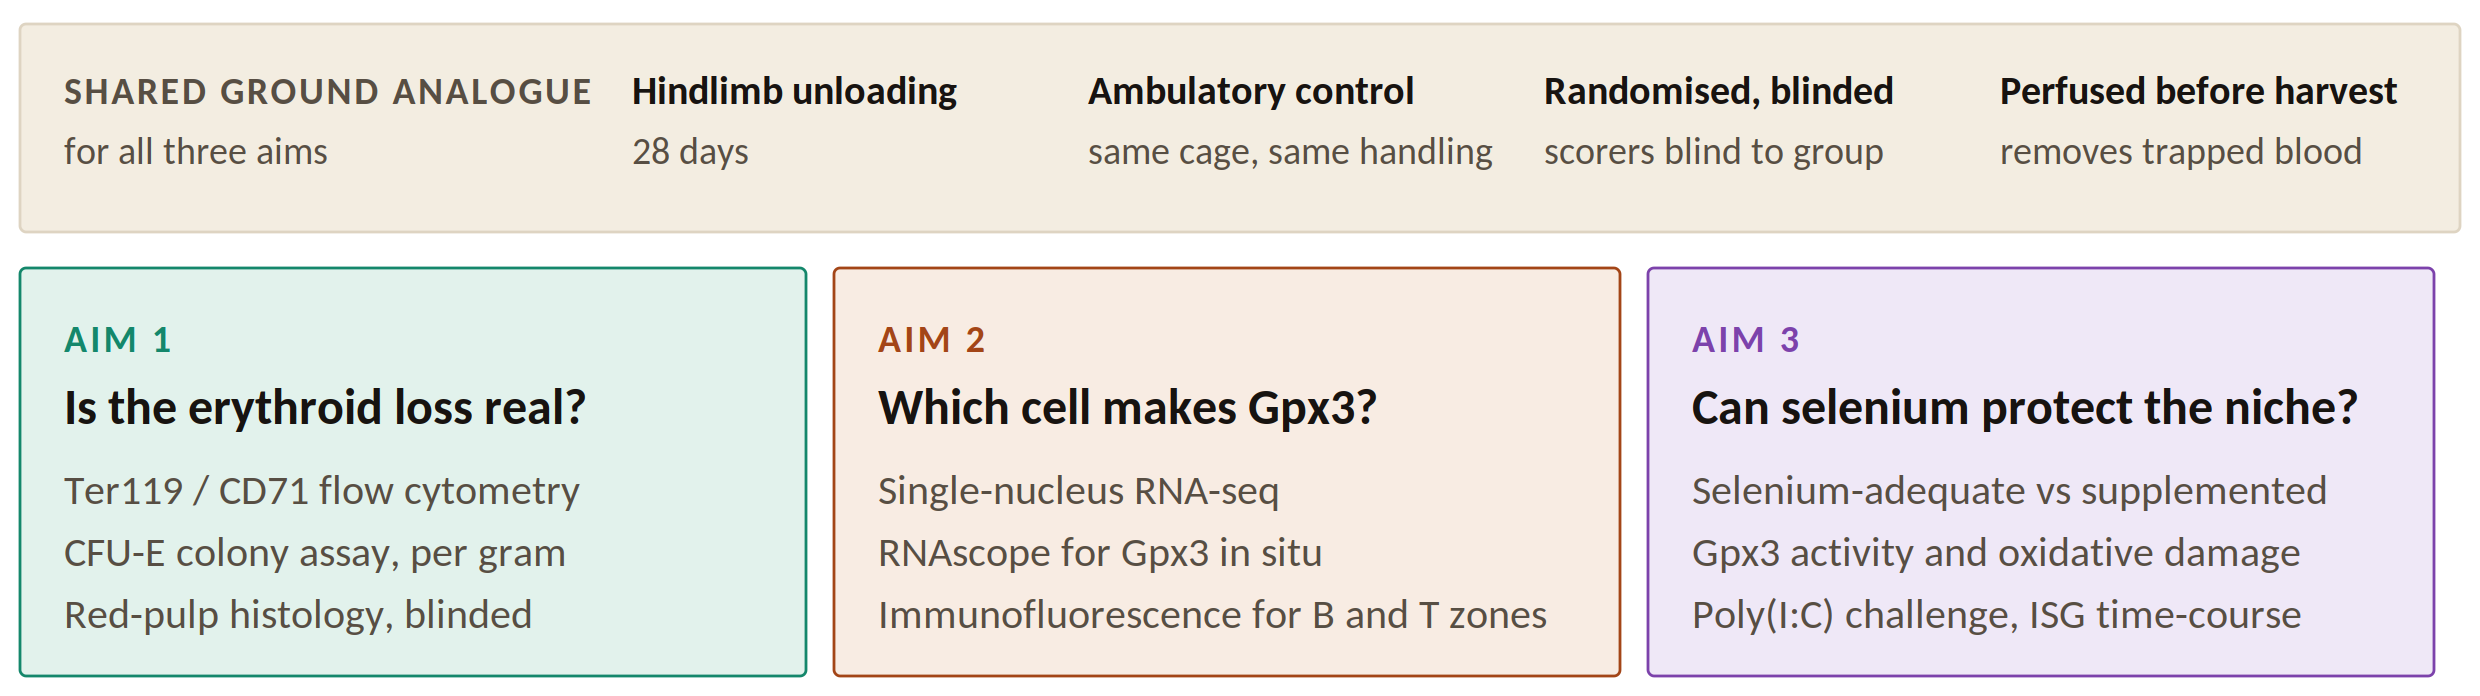

figures/fig_expected.png


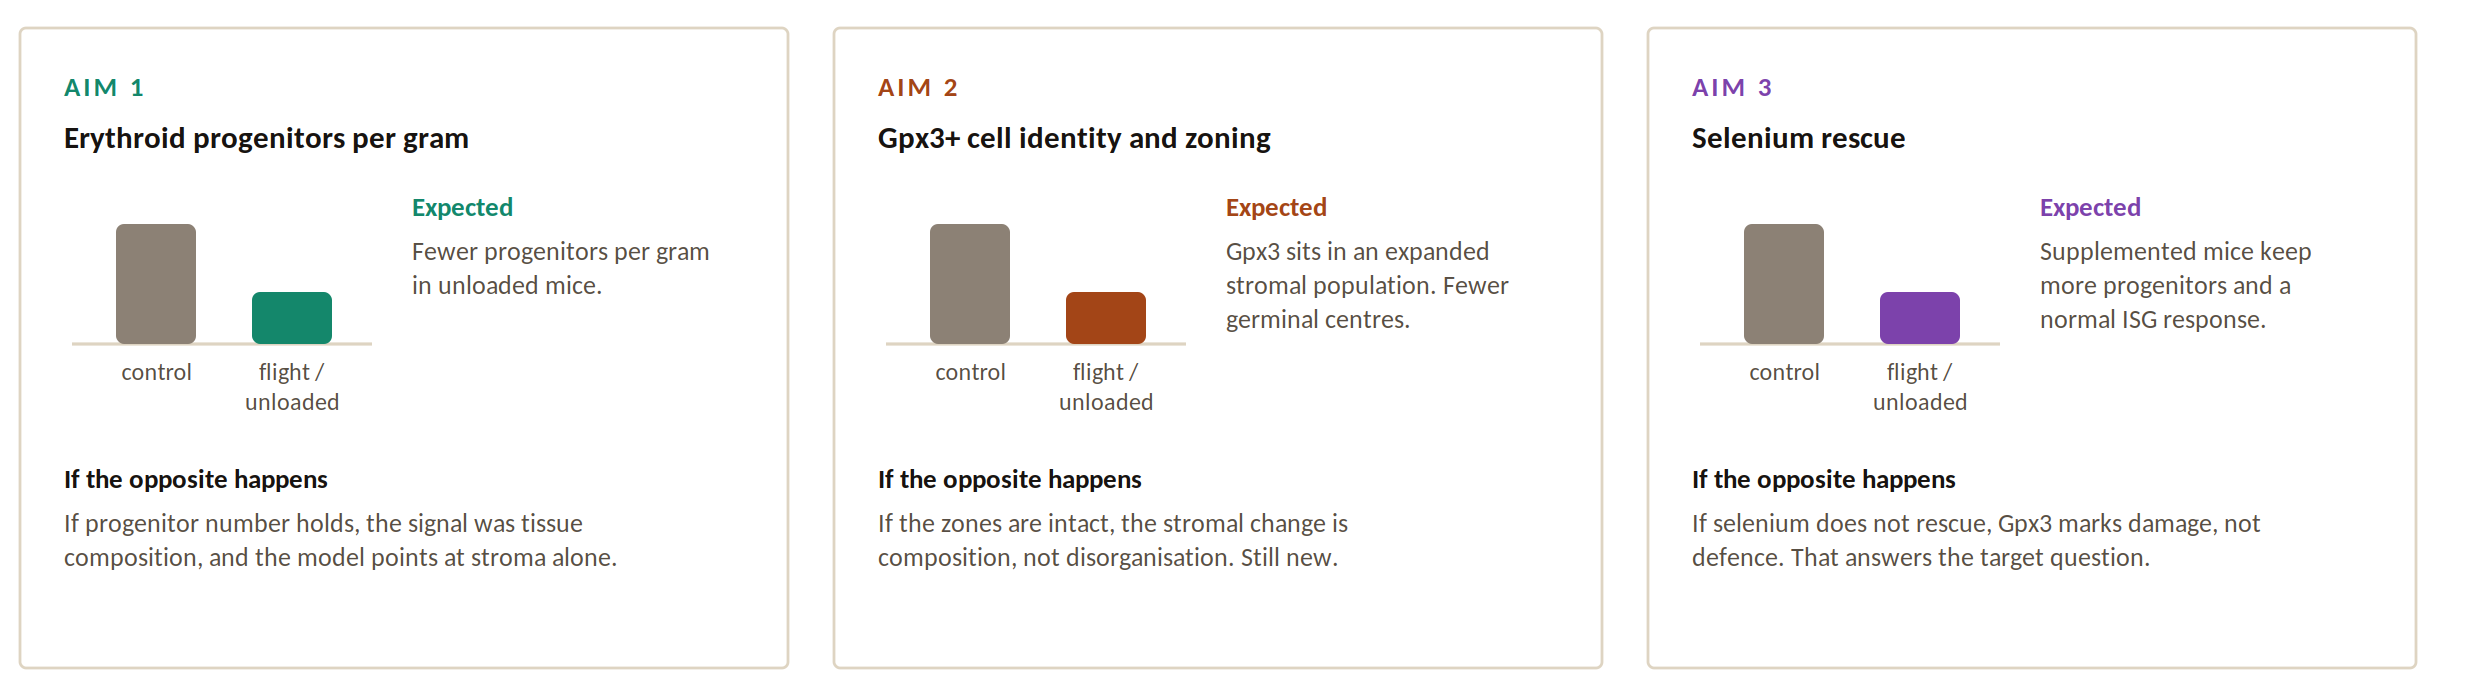

figures/fig_mission.png


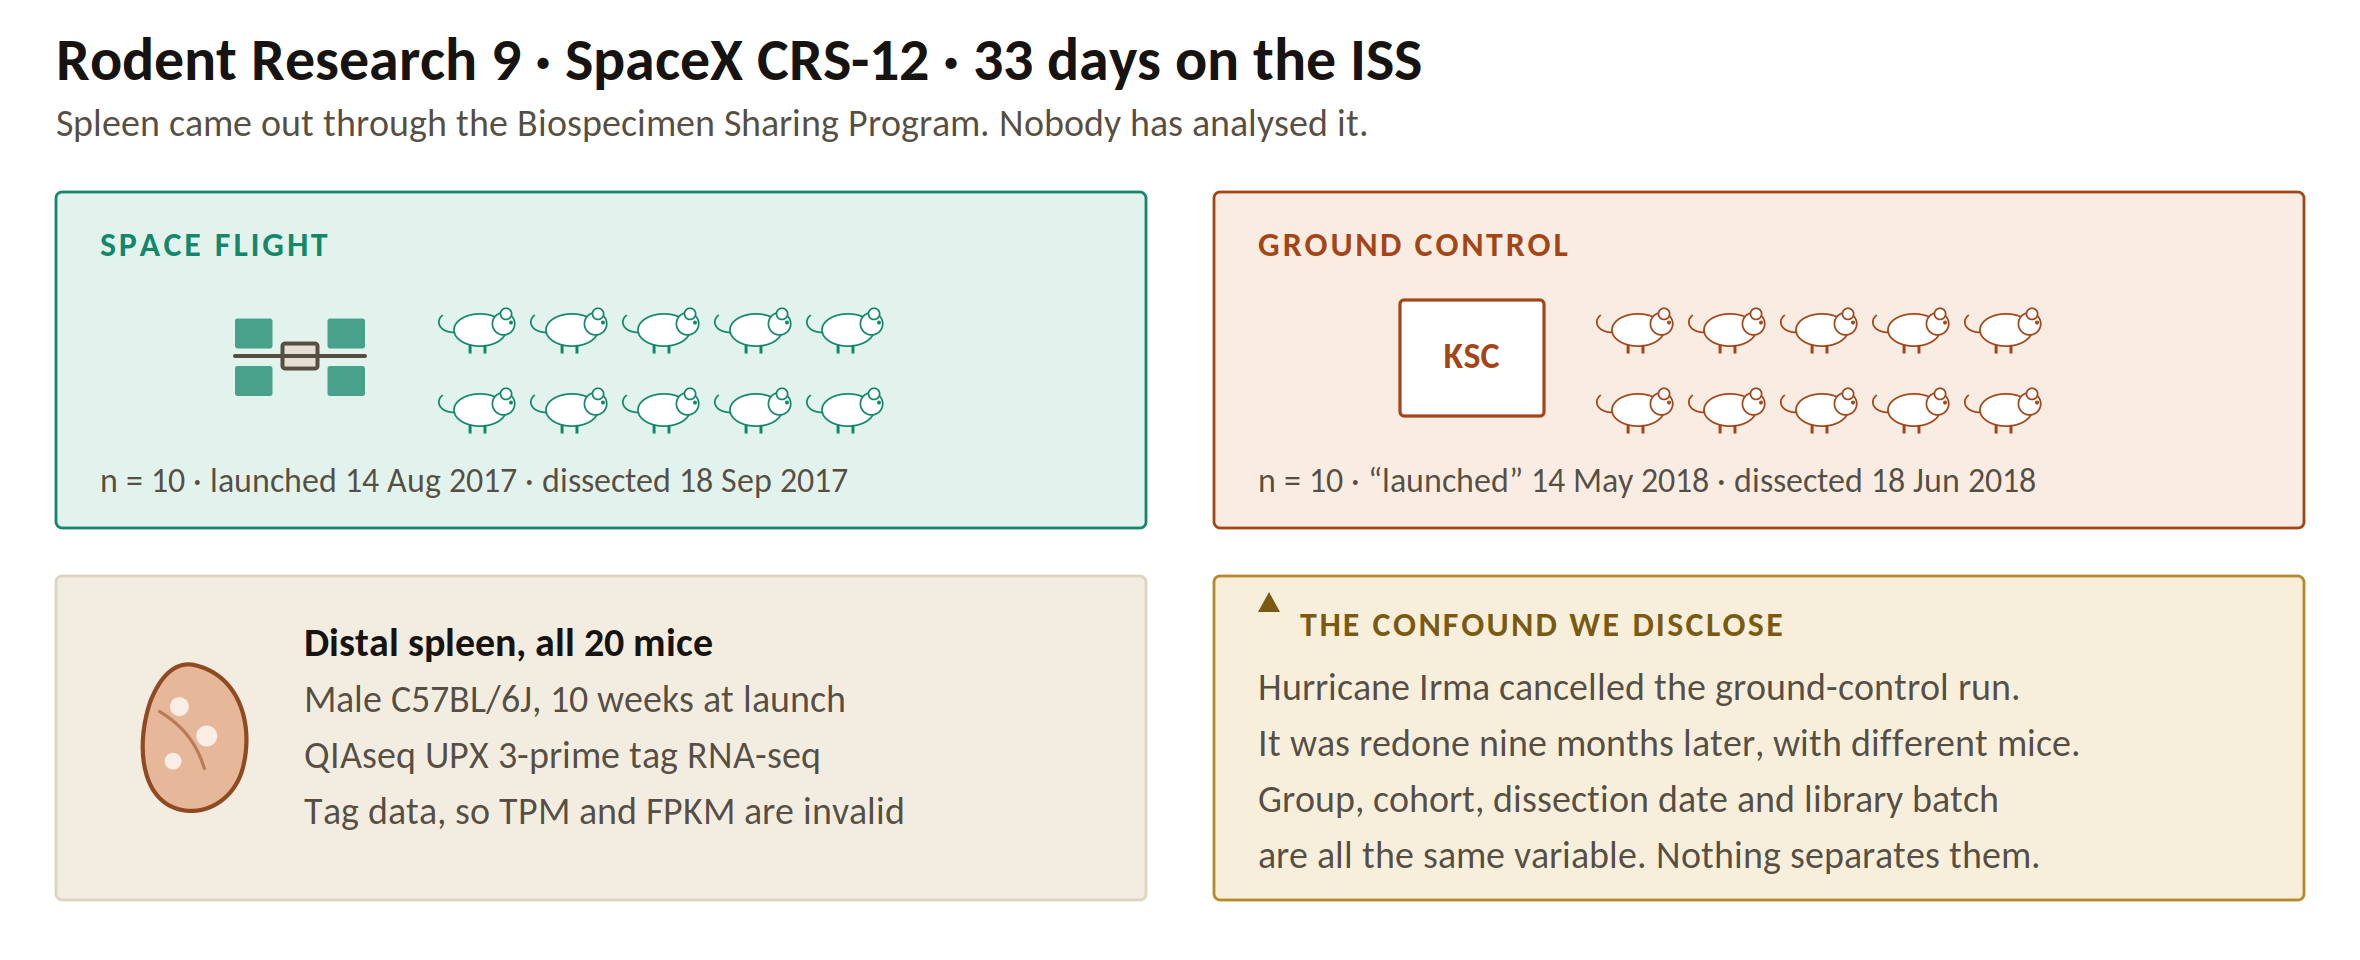

figures/fig_model.png


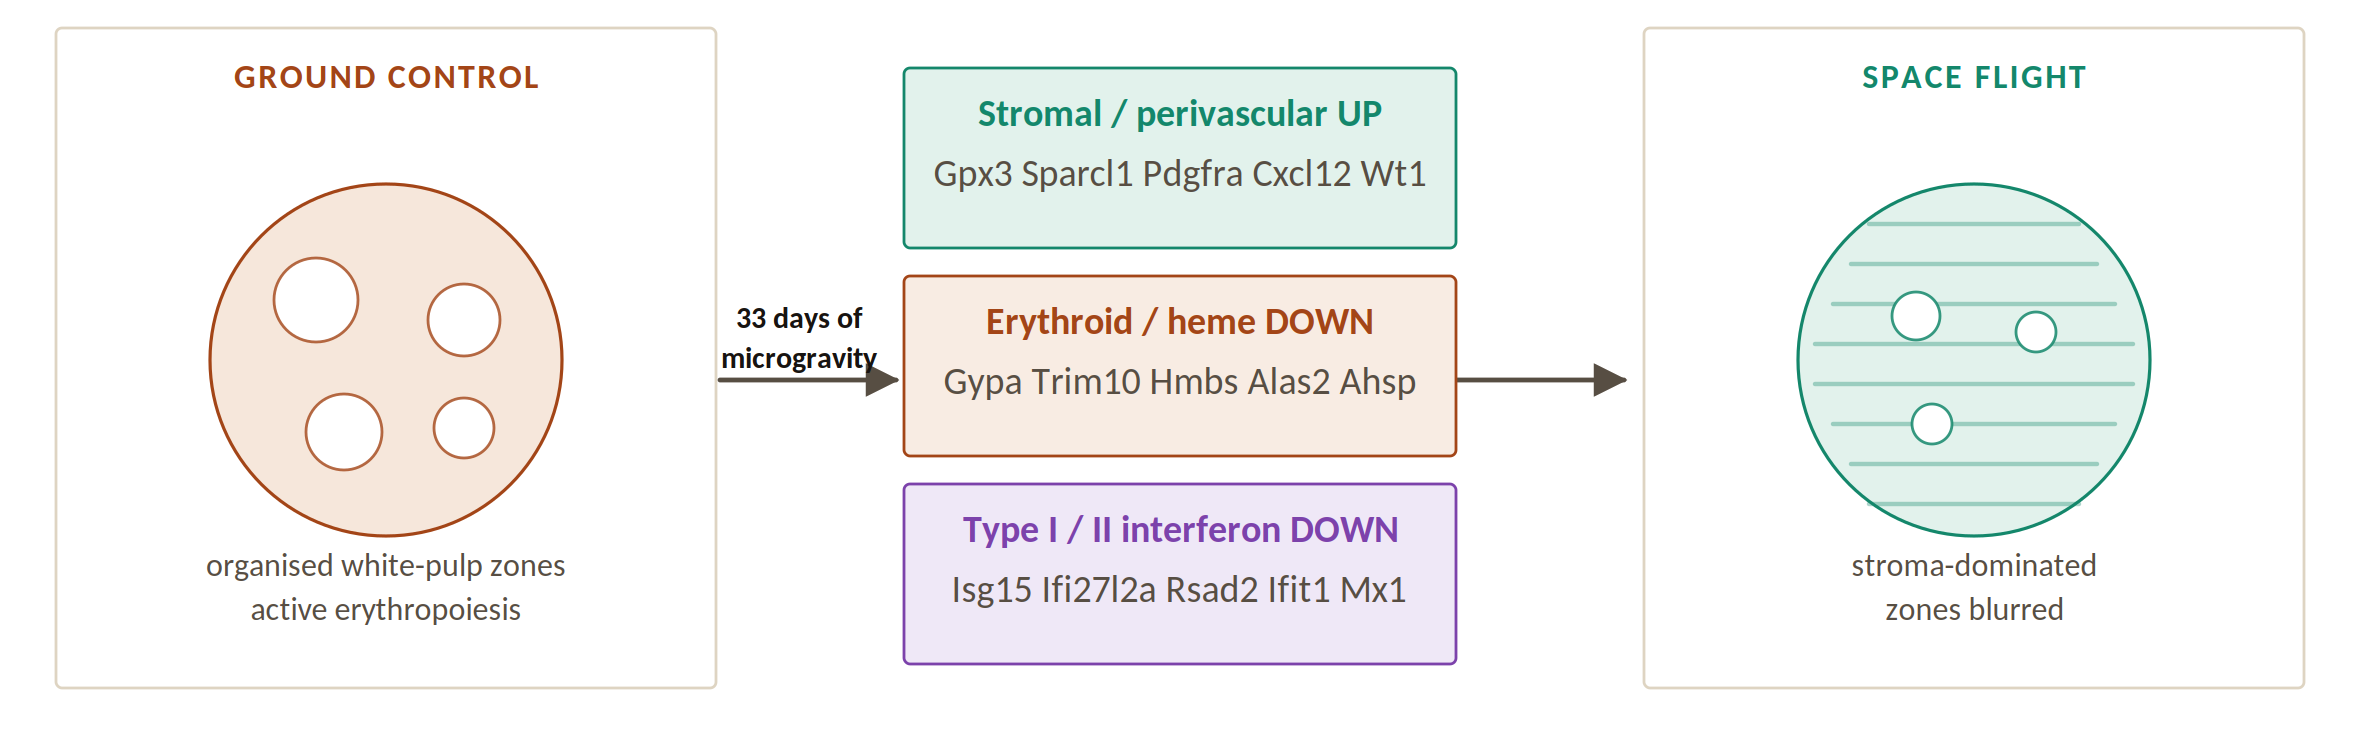

figures/fig_pipeline.png


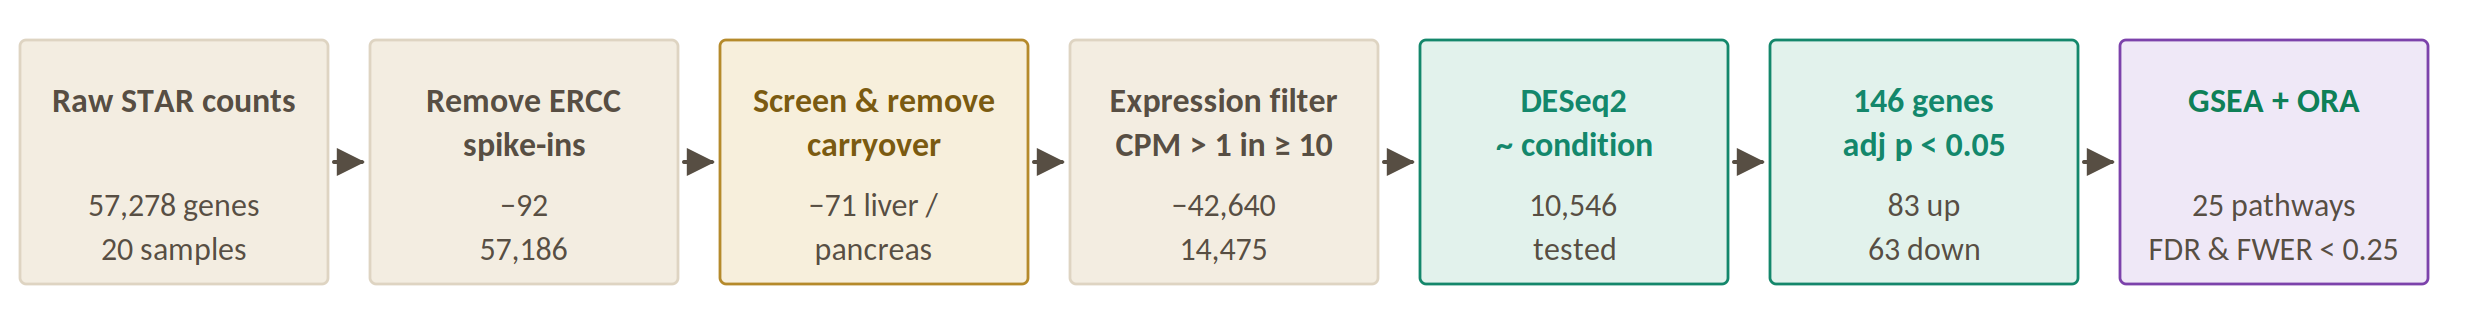

In [8]:
import glob, os
from IPython.display import Image, display
for f in sorted(glob.glob(f"{FIG}/fig_*.png")):
    if os.path.exists(f.replace(".png", ".svg")):
        print(f)
        display(Image(filename=f, width=900))